# Chapter 3: When the model goes stale: how will we know?

*Staleness: the monitoring rule and the weakest segment*

**Who needs the answer.** The gym's owner, who will not reread the model each month and needs one rule that says when to stop trusting it, and the trainer at the front desk who runs the calls.

**The questions on the way.** Which number tells us the model has drifted? How big a gap is luck? What does a rule need to be checkable? Which plan type is the model weakest on, and can we trust the reading?

**What you will be able to do.** Write a monitoring rule with its number, ceiling, window and owner, size the ceiling from the sample, and read a segment's gap with its band.

**Search terms.** model drift, model monitoring, calibration, segment analysis

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)
import numpy as np, pandas as pd

# Invented for teaching: six months of comeback calls, 200 a month, scored by a model built on January to March.
months = pd.DataFrame({
    "month":    ["Apr", "May", "Jun", "Jul", "Aug", "Sep"],
    "calls":    [200, 200, 200, 200, 200, 200],
    "promised": [0.12, 0.12, 0.13, 0.12, 0.12, 0.13],     # the mean score of the members called
    "returned": [24, 22, 28, 40, 44, 50],                 # members who came back
})
months["real"] = months.returned / months.calls
months

,month,calls,promised,returned,real
0,Apr,200,0.12,24,0.12
1,May,200,0.12,22,0.11
2,Jun,200,0.13,28,0.14
3,Jul,200,0.12,40,0.20
4,Aug,200,0.12,44,0.22
5,Sep,200,0.13,50,0.25


## Which rule catches the drift, and in which month?

A rival gym nearby closed in July (invented), and lapsed members started returning on their own. The model still promises about 12 in 100.

**Predict before you run.** The rule is: alarm when the real share sits more than 5 points from the promise two months running. In which month does it fire? a) April; b) July; c) August; d) never, since the scores did not change.

In [2]:
n, p0 = 200, 0.12
band = 2 * np.sqrt(p0 * (1 - p0) / n)          # how far luck moves a share of 200 calls
CEILING = 0.05
months["gap"] = (months.real - months.promised).round(3)
months["over"] = months.gap.abs() > CEILING
months["alarm"] = months.over & months.over.shift(1, fill_value=False)
print(f"luck band at 200 calls: about {band:.3f}, so the ceiling sits at {CEILING}")
months[["month", "promised", "real", "gap", "over", "alarm"]]

luck band at 200 calls: about 0.046, so the ceiling sits at 0.05


,month,promised,real,gap,over,alarm
0,Apr,0.12,0.12,0.00,False,False
1,May,0.12,0.11,-0.01,False,False
2,Jun,0.13,0.14,0.01,False,False
3,Jul,0.12,0.20,0.08,True,False
4,Aug,0.12,0.22,0.10,True,True
5,Sep,0.13,0.25,0.12,True,True


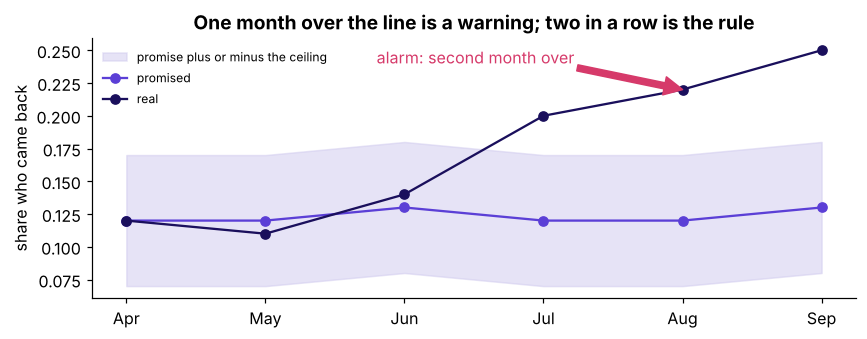

PASS  the luck band at 200 calls sits under the ceiling
PASS  the alarm fires in August, the second month over the line


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(months))
ax.fill_between(x, months.promised - CEILING, months.promised + CEILING, color=LILAC, alpha=0.5, label="promise plus or minus the ceiling")
ax.plot(x, months.promised, "-o", color=VIOLET, label="promised")
ax.plot(x, months.real, "-o", color=INK, label="real")
fire = int(months.index[months.alarm][0])
ax.annotate("alarm: second month over", (fire, months.real[fire]), (fire - 2.2, 0.24), color=ROSE, arrowprops=dict(color=ROSE))
ax.set_xticks(x); ax.set_xticklabels(months.month); ax.set_ylabel("share who came back"); ax.legend(frameon=False, fontsize=8)
ax.set_title("One month over the line is a warning; two in a row is the rule")
plt.tight_layout(); plt.show()
check("the luck band at 200 calls sits under the ceiling", band < CEILING)
check("the alarm fires in August, the second month over the line", months.loc[months.alarm, "month"].iloc[0] == "Aug")

**What happened.** The answer is c. July is over the line once, which could be luck; August makes two in a row. "Retrain every month" is the common wrong answer: a calendar fires when nothing has changed and waits a month when something has. A rule has four parts: the number (the real share against the promise), the ceiling (5 points, just above luck at 200 calls), the window (two months running) and the owner (the front-desk manager pauses the list).

## Which plan type is the model weakest on, and can we trust the reading?

September's 200 calls split by plan. A small group swings by luck, so each gap carries its band: `2 x sqrt(p x (1 - p) / n)`, the Week 1 sample-size rule.

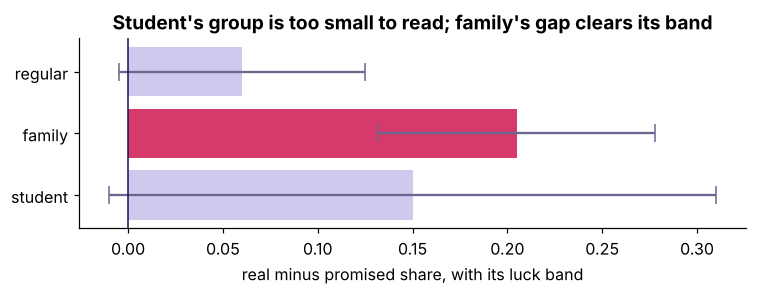

,plan,calls,promised,returned,real,gap,band,readable
0,student,20,0.15,6,0.300,0.150,0.160,False
1,family,80,0.12,26,0.325,0.205,0.073,True
2,regular,100,0.12,18,0.180,0.060,0.065,False


In [4]:
seg = pd.DataFrame({"plan": ["student", "family", "regular"], "calls": [20, 80, 100],
                    "promised": [0.15, 0.12, 0.12], "returned": [6, 26, 18]})   # invented, adds to September's 50
seg["real"] = seg.returned / seg.calls
seg["gap"] = (seg.real - seg.promised).round(3)
seg["band"] = (2 * np.sqrt(seg.promised * (1 - seg.promised) / seg.calls)).round(3)
seg["readable"] = seg.gap.abs() > seg.band
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(seg.plan, seg.gap, xerr=seg.band, color=[ROSE if r else LILAC for r in seg.readable], ecolor=MUTED, capsize=6)
ax.axvline(0, color=INK, lw=1); ax.set_xlabel("real minus promised share, with its luck band")
ax.set_title("Student's group is too small to read; family's gap clears its band")
plt.tight_layout(); plt.show()
seg

In [5]:
check("the student band is wider than the family band", seg.set_index("plan").loc["student", "band"] > seg.set_index("plan").loc["family", "band"])
check("only the family gap clears its band", seg.loc[seg.readable, "plan"].tolist() == ["family"])

PASS  the student band is wider than the family band
PASS  only the family gap clears its band


## What did this chapter establish?

| Question | Answer |
|---|---|
| The number to watch | The real share among called members against the share the model promised |
| How big a gap is luck? | About 4.6 points at 200 calls, so the ceiling is 5 |
| The rule | Number, ceiling, window, owner: over 5 points two months running, the manager pauses the list |
| The weakest segment | Family, whose gap clears its band; student's gap is wide too, on a group too small to read |

Drift detection methods and retraining pipelines are named here and taught from Week 14 on. Chapter 4 moves the same machinery to a business where the expensive mistake is the other one.